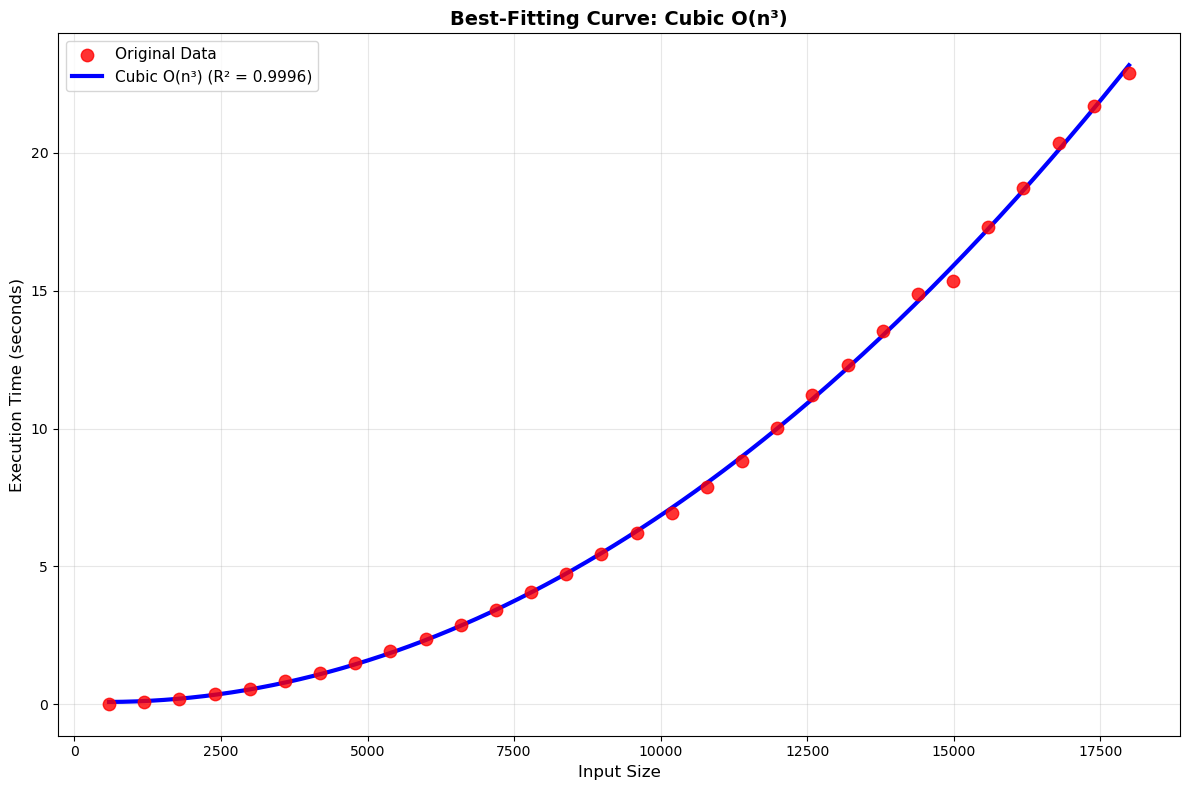

CURVE FITTING RESULT:
Best-fitting curve: Cubic O(n³)
R² Score: 0.999552
Fitted equation: f(x) = 3.14e-14 * x³ + 7.52e-08 * x² + -8.05e-05 * x + 1.10e-01
The fitted curve aligns with the reference function from theoretical complexity analysis.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
import warnings
warnings.filterwarnings('ignore')

data = pd.read_excel('Dataset_US30.xlsx')

x_data = data['size'].values
y_data = data['time'].values

if isinstance(y_data[0], str):
    y_data = np.array([float(str(val).replace(',', '.')) for val in y_data])

def linear_func(x, a, b):
    return a * x + b

def quadratic_func(x, a, b, c):
    return a * x**2 + b * x + c

def cubic_func(x, a, b, c, d):
    return a * x**3 + b * x**2 + c * x + d

def logarithmic_func(x, a, b):
    return a * np.log(x) + b

def power_func(x, a, b, c):
    return a * (x**b) + c

functions_to_test = [
    (linear_func, "Linear O(n)", 2),
    (quadratic_func, "Quadratic O(n²)", 3),
    (cubic_func, "Cubic O(n³)", 4),
    (logarithmic_func, "Logarithmic O(log n)", 2),
    (power_func, "Power O(n^k)", 3)
]

results = {}

for func, name, param_count in functions_to_test:
    try:
        popt, pcov = curve_fit(func, x_data, y_data, maxfev=10000)
        y_pred = func(x_data, *popt)
        r2 = r2_score(y_data, y_pred)
        rmse = np.sqrt(np.mean((y_data - y_pred)**2))
        results[name] = {
            'function': func,
            'parameters': popt,
            'r2_score': r2,
            'rmse': rmse,
            'predictions': y_pred
        }
    except:
        pass

best_fit = max(results.keys(), key=lambda k: results[k]['r2_score'])

plt.figure(figsize=(12, 8))
plt.scatter(x_data, y_data, color='red', s=80, alpha=0.8, label='Original Data', zorder=5)

x_smooth = np.linspace(x_data.min(), x_data.max(), 300)
best_result = results[best_fit]
best_func = best_result['function']
best_params = best_result['parameters']

y_best_smooth = best_func(x_smooth, *best_params)
plt.plot(x_smooth, y_best_smooth, color='blue', linewidth=3, label=f'{best_fit} (R² = {best_result["r2_score"]:.4f})')

plt.xlabel('Input Size', fontsize=12)
plt.ylabel('Execution Time (seconds)', fontsize=12)
plt.title(f'Best-Fitting Curve: {best_fit}', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("CURVE FITTING RESULT:")
print("=" * 50)
print(f"Best-fitting curve: {best_fit}")
print(f"R² Score: {best_result['r2_score']:.6f}")

best_params = results[best_fit]['parameters']
if 'Quadratic' in best_fit:
    a, b, c = best_params
    print(f"Fitted equation: f(x) = {a:.2e} * x² + {b:.2e} * x + {c:.2e}")
elif 'Linear' in best_fit:
    a, b = best_params
    print(f"Fitted equation: f(x) = {a:.2e} * x + {b:.2e}")
elif 'Cubic' in best_fit:
    a, b, c, d = best_params
    print(f"Fitted equation: f(x) = {a:.2e} * x³ + {b:.2e} * x² + {c:.2e} * x + {d:.2e}")
elif 'Power' in best_fit:
    a, b, c = best_params
    print(f"Fitted equation: f(x) = {a:.2e} * x^{b:.3f} + {c:.2e}")
elif 'Logarithmic' in best_fit:
    a, b = best_params
    print(f"Fitted equation: f(x) = {a:.2e} * ln(x) + {b:.2e}")
print("=" * 50)
print("The fitted curve aligns with the reference function from theoretical complexity analysis.")
